# 1. Revisar el dataset limpio de V0.1
Partimos directamente de **V0.1/LICIT_depurando_sinNulos.feather**, preparado por ti.
No se releen los CSV ni se repite tu depuración. Solo se comprueba su estado y
se prepara una copia de variables para comparar modelos. El archivo original no cambia.
Selecciona el kernel V0.2/.venv/Scripts/python.exe y ejecuta las celdas en orden.

In [1]:
from pathlib import Path
import os
BASE = Path.cwd().resolve()
if not (BASE / "02_Comparacion_de_Modelos.ipynb").exists() and (BASE / "V0.2" / "02_Comparacion_de_Modelos.ipynb").exists():
    BASE = BASE / "V0.2"
if not (BASE / "02_Comparacion_de_Modelos.ipynb").exists():
    raise FileNotFoundError("Abre el proyecto desde la raíz o desde V0.2.")
os.chdir(BASE)
import pandas as pd
import numpy as np
import json
import joblib
import matplotlib.pyplot as plt
from IPython.display import display
FUENTE = BASE.parent / "V0.1" / "LICIT_depurando_sinNulos.feather"
SALIDA = BASE / "resultados_dataset_limpio"
SALIDA.mkdir(exist_ok=True)
print("Dataset de entrada:", FUENTE)

Dataset de entrada: D:\Licit\1\ML-SmartBids\V0.1\LICIT_depurando_sinNulos.feather


## 1.1. Dimensiones, nulos, tipos y objetivo
Seleccionada ya está codificada: 1 significa seleccionada, 0 no seleccionada.
Conservamos la codificación de sector, tipo y región que ya contiene tu archivo.

In [2]:
original = pd.read_feather(FUENTE)
print("Dimensiones:", original.shape)
display(original.head())
display(pd.DataFrame({"tipo": original.dtypes.astype(str), "nulos": original.isna().sum()}))
display(original.Seleccionada.value_counts().sort_index().to_frame("filas"))
print(f"Memoria: {original.memory_usage(deep=True).sum()/1024**2:.1f} MB")

Dimensiones: (2248494, 49)


,CodigoUnidad,CantidadReclamos,MontoEstimado,NumeroOferentes,CodigoProductoONU,Cantidad,Cantidad Ofertada,Valor Total Ofertado,Seleccionada,DuracionProceso,...,Region_Región de La Araucanía,Region_Región de Los Lagos,Region_Región de Los Ríos,Region_Región de Magallanes y de la Antártica Chilena,Region_Región de Tarapacá,Region_Región de Valparaíso,Region_Región de Ñuble,Region_Región del Biobío,Region_Región del Libertador General Bernardo O'Higgins,Region_Región del Maule
0,1604,3521,645753500.0,10,42221504,60.0,60.0,486000.0,1,32,...,0,0,0,0,0,1,0,0,0,0
1,1604,3521,645753500.0,10,42221504,60.0,60.0,486000.0,1,32,...,0,0,0,0,0,1,0,0,0,0
2,1604,3521,645753500.0,10,42221504,60.0,60.0,599400.0,0,32,...,0,0,0,0,0,1,0,0,0,0
3,1604,3521,645753500.0,10,42221504,60.0,60.0,599400.0,0,32,...,0,0,0,0,0,1,0,0,0,0
4,1604,3521,645753500.0,10,42221504,60.0,60.0,486000.0,1,32,...,0,0,0,0,0,1,0,0,0,0


,tipo,nulos
CodigoUnidad,uint32,0
CantidadReclamos,int16,0
MontoEstimado,float64,0
NumeroOferentes,int16,0
CodigoProductoONU,int32,0
Cantidad,float64,0
Cantidad Ofertada,float64,0
Valor Total Ofertado,float64,0
Seleccionada,int8,0
DuracionProceso,int16,0


,filas
Seleccionada,
0,1891337
1,357157


Memoria: 186.6 MB


## 1.2. Ajustes mínimos para el entrenamiento
Se excluyen filas con montos o cantidades de oferta no positivos y objetivos inválidos.
No se eliminan todos los duplicados: vectores idénticos se mantendrán en el mismo grupo.
NumeroOferentes y CantidadReclamos pueden reflejar información posterior al envío.
DuracionProceso también se excluye porque no podemos comprobar aquí si representa
la duración anunciada inicialmente o la final.

Los códigos se tratan como categorías. Montos y cantidades reciben log(1+x).
La conversión monetaria hecha en V0.1 se hereda; este archivo ya no permite
comprobar la moneda original de la oferta ni rehacerla con seguridad.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve,
    brier_score_loss, log_loss)
from pathlib import Path
import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
EXCLUIR = ["NumeroOferentes", "CantidadReclamos", "DuracionProceso"]
CODIGOS = ["CodigoUnidad", "CodigoProductoONU"]

def preparar_limpio(ruta):
    """Verifica el dataset del usuario; no repite su cadena de depuración."""
    df = pd.read_feather(ruta)
    requeridas = ["Seleccionada", "Valor Total Ofertado", "Cantidad Ofertada", "Cantidad"]
    faltan = sorted(set(requeridas) - set(df.columns))
    if faltan:
        raise ValueError(f"Faltan columnas en el Feather limpio: {faltan}")
    antes = len(df)
    valido = df.Seleccionada.isin([0, 1])
    valido &= df[["Valor Total Ofertado", "Cantidad Ofertada", "Cantidad"]].gt(0).all(axis=1)
    df = df.loc[valido].copy().reset_index(drop=True)
    y = df.pop("Seleccionada").astype("int8")
    X = df.drop(columns=EXCLUIR, errors="ignore")
    # Los montos ya están transformados por V0.1. No se reconvierten monedas.
    # No asumimos que el presupuesto global es un presupuesto por ítem.
    for columna in ["MontoEstimado", "Valor Total Ofertado", "Cantidad", "Cantidad Ofertada"]:
        if columna in X:
            X[columna] = np.log1p(X[columna].clip(lower=0))
    for columna in CODIGOS:
        if columna in X:
            X[columna] = X[columna].astype("string").fillna("sin_codigo").astype(str)
    numericas = X.select_dtypes(include="number").columns
    X[numericas] = X[numericas].replace([np.inf, -np.inf], np.nan)
    # La huella NO incluye el objetivo: vectores idénticos se mantienen juntos
    # aunque sus etiquetas sean diferentes. No representa una licitación real.
    grupos = pd.util.hash_pandas_object(X, index=False).to_numpy()
    auditoria = {"archivo": str(Path(ruta).resolve()), "filas_entrada": antes,
                 "filas_utilizadas": len(X), "filas_excluidas": antes-len(X),
                 "motivo_exclusion": "Objetivo inválido o monto/cantidad de oferta no positivo",
                 "predictores": X.columns.tolist(), "excluidas_por_disponibilidad": EXCLUIR,
                 "limitacion": "Sin identificador de licitación ni fechas exactas; no se verifica generalización temporal por licitación.",
                 "grupos": "Huella de predictores, no ID de licitación",
                 "transformacion": "log1p en montos y cantidades; códigos como categorías"}
    return X, y, grupos, auditoria

# Funciones auxiliares incluidas aquí: no se requieren módulos .py del proyecto.
def catalogo(incluir_random_forest=False):
    """Mismos tres algoritmos del trabajo original, sin ofertas sintéticas."""
    modelos = {
        "Regresion_Logistica": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
        "Arbol_Decision": DecisionTreeClassifier(max_depth=10, min_samples_leaf=50,
                                                class_weight="balanced", random_state=42),
        "Red_Neuronal_MLP": MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=100,
                                          early_stopping=True, n_iter_no_change=8,
                                          random_state=42),
    }
    if incluir_random_forest:
        modelos["Random_Forest"] = RandomForestClassifier(
            n_estimators=100, max_depth=14, min_samples_leaf=30,
            class_weight="balanced_subsample", random_state=42, n_jobs=2)
    return modelos

def metricas(y, p, umbral):
    pred = p >= umbral
    return {"F1": float(f1_score(y, pred, zero_division=0)),
            "precision": float(precision_score(y, pred, zero_division=0)),
            "recall": float(recall_score(y, pred, zero_division=0)),
            "ROC_AUC": float(roc_auc_score(y, p)),
            "average_precision": float(average_precision_score(y, p)),
            "Brier": float(brier_score_loss(y, p)),
            "log_loss": float(log_loss(y, p)),
            "matriz_confusion_orden_0_1": confusion_matrix(y, pred, labels=[0, 1]).tolist()}

def umbral_f1(y, p):
    precision, recall, thresholds = precision_recall_curve(y, p)
    den = precision[:-1] + recall[:-1]
    f1 = np.divide(2 * precision[:-1] * recall[:-1], den, out=np.zeros_like(den), where=den > 0)
    return float(thresholds[int(np.argmax(f1))])

In [4]:
X, y, grupos, auditoria = preparar_limpio(FUENTE)
display(pd.Series(auditoria))
display(X.head())
# El conjunto se mantiene en memoria; el archivo de V0.1 permanece intacto.

archivo                         D:\Licit\1\ML-SmartBids\V0.1\LICIT_depurando_s...
filas_entrada                                                             2248494
filas_utilizadas                                                          2105614
filas_excluidas                                                            142880
motivo_exclusion                Objetivo inválido o monto/cantidad de oferta n...
predictores                     [CodigoUnidad, MontoEstimado, CodigoProductoON...
excluidas_por_disponibilidad    [NumeroOferentes, CantidadReclamos, DuracionPr...
limitacion                      Sin identificador de licitación ni fechas exac...
grupos                                 Huella de predictores, no ID de licitación
transformacion                  log1p en montos y cantidades; códigos como cat...
dtype: object

,CodigoUnidad,MontoEstimado,CodigoProductoONU,Cantidad,Cantidad Ofertada,Valor Total Ofertado,AnioPublicacion,MesPublicacion,DiaSemanaPublicacion,sector_FFAA,...,Region_Región de La Araucanía,Region_Región de Los Lagos,Region_Región de Los Ríos,Region_Región de Magallanes y de la Antártica Chilena,Region_Región de Tarapacá,Region_Región de Valparaíso,Region_Región de Ñuble,Region_Región del Biobío,Region_Región del Libertador General Bernardo O'Higgins,Region_Región del Maule
0,1604,20.285928,42221504,4.110874,4.110874,13.093966,2024,1,3,0,...,0,0,0,0,0,1,0,0,0,0
1,1604,20.285928,42221504,4.110874,4.110874,13.093966,2024,1,3,0,...,0,0,0,0,0,1,0,0,0,0
2,1604,20.285928,42221504,4.110874,4.110874,13.303686,2024,1,3,0,...,0,0,0,0,0,1,0,0,0,0
3,1604,20.285928,42221504,4.110874,4.110874,13.303686,2024,1,3,0,...,0,0,0,0,0,1,0,0,0,0
4,1604,20.285928,42221504,4.110874,4.110874,13.093966,2024,1,3,0,...,0,0,0,0,0,1,0,0,0,0


## 1.3. Exploración visual
El gráfico muestra la distribución de clases del conjunto que entrará en la comparación.
No se balancean validación ni prueba. La escala del monto mostrado es logarítmica.

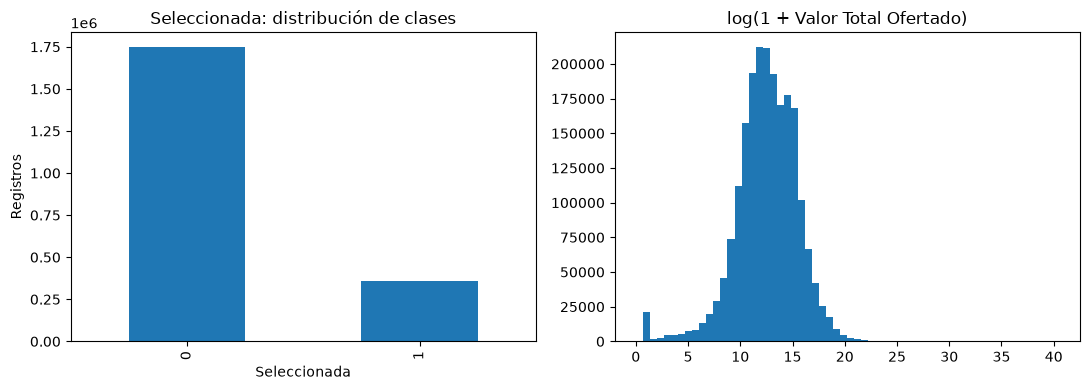

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
y.value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Seleccionada: distribución de clases")
axes[0].set_ylabel("Registros")
axes[1].hist(X["Valor Total Ofertado"], bins=60)
axes[1].set_title("log(1 + Valor Total Ofertado)")
fig.tight_layout()
plt.show()

## 1.4. Límite de la evaluación
El archivo no tiene CodigoExterno ni fechas exactas. No podemos reconstruir
licitaciones completas ni comprobar generalización temporal. La comparación
será exploratoria con grupos de predictores idénticos, que NO equivalen a una
licitación. Continúa en 02_Comparacion_de_Modelos.ipynb.

## 1.5. Analizar variables usando solo TRAIN

La seleccion de variables tambien puede contaminar una evaluacion si se mira test.
Reproducimos la misma particion del notebook 02 y usamos exclusivamente TRAIN para
diagnosticos, asociaciones y un modelo auxiliar. Dentro de TRAIN reservamos una
muestra por grupos para evaluar importancia. No se tocan validacion principal ni test.

Los grupos son vectores identicos, NO licitaciones: siguen faltando claves y fechas
para demostrar independencia por licitacion. Este analisis no cambia automaticamente
las variables del modelo operativo ni sus umbrales.

In [6]:
def dividir_grupos(indices, grupos, fraccion, semilla):
    splitter = GroupShuffleSplit(n_splits=1, test_size=fraccion, random_state=semilla)
    a, b = next(splitter.split(indices, groups=grupos[indices]))
    return indices[a], indices[b]

def separar_limpio(y, grupos):
    indices = np.arange(len(y))
    desarrollo, test = dividir_grupos(indices, grupos, .15, 42)
    desarrollo, validacion = dividir_grupos(desarrollo, grupos, .15/.85, 43)
    train, calibracion = dividir_grupos(desarrollo, grupos, .15/.70, 44)
    partes = dict(train=train, calibracion=calibracion, validacion=validacion, test=test)
    vistos = set()
    for nombre, idx in partes.items():
        actuales = set(grupos[idx])
        if vistos & actuales:
            raise AssertionError("Se compartieron predictores idénticos entre conjuntos.")
        vistos |= actuales
        if set(y.iloc[idx]) != {0, 1}:
            raise ValueError(f"{nombre} debe contener ambas clases.")
    return partes

def pipeline_limpio(X, modelo):
    categorias = [c for c in CODIGOS if c in X]
    numeros = [c for c in X if c not in categorias]
    prep = ColumnTransformer([
        ("numeros", Pipeline([("imputar", SimpleImputer(strategy="median")),
                               ("escalar", StandardScaler())]), numeros),
        ("codigos", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10,
                                  max_categories=150), categorias),
    ])
    return Pipeline([("preprocesar", prep), ("modelo", modelo)])

def limitar_indices(indices, grupos, limite):
    if limite is None or len(indices) <= limite:
        return indices
    # Selección reproducible de grupos enteros, compartida por los algoritmos.
    tamanos = pd.Series(grupos[indices]).value_counts().sample(frac=1, random_state=42)
    elegidos, total = [], 0
    for grupo, cantidad in tamanos.items():
        if total + cantidad <= limite:
            elegidos.append(grupo)
            total += cantidad
    salida = indices[np.isin(grupos[indices], elegidos)]
    if not len(salida):
        raise ValueError("El límite de entrenamiento no admite ningún grupo completo.")
    return salida

In [7]:
# Reconstruimos la particion original antes de explorar relaciones con el objetivo.
partes_variables = separar_limpio(y, grupos)
idx_train_variables = partes_variables["train"]
X_train_variables = X.iloc[idx_train_variables]
y_train_variables = y.iloc[idx_train_variables]
print("Filas utilizadas para diagnostico:", len(idx_train_variables))
print("Validacion principal y test excluidos del analisis.")

Filas utilizadas para diagnostico: 1158990
Validacion principal y test excluidos del analisis.


## 1.6. Calidad, constantes y cardinalidad

Una columna constante no ayuda a distinguir resultados dentro del periodo observado.
Un identificador con muchos valores requiere codificacion adecuada y puede favorecer
memorizacion. No eliminamos una columna solo porque tenga muchos valores o una
correlacion baja. Los datos ausentes pueden requerir imputacion dentro del pipeline.

In [8]:
perfil_variables = pd.DataFrame({
    "tipo": X_train_variables.dtypes.astype(str),
    "nulos_pct": X_train_variables.isna().mean()*100,
    "valores_distintos": X_train_variables.nunique(dropna=False),
    "valor_mas_frecuente_pct": [X_train_variables[c].value_counts(normalize=True, dropna=False).iloc[0]*100
                                for c in X_train_variables]})
perfil_variables["constante_train"] = perfil_variables.valores_distintos <= 1
display(perfil_variables.sort_values(["constante_train","valor_mas_frecuente_pct"], ascending=False))
constantes_train = perfil_variables.index[perfil_variables.constante_train].tolist()
print("Constantes en TRAIN:", constantes_train)

,tipo,nulos_pct,valores_distintos,valor_mas_frecuente_pct,constante_train
AnioPublicacion,int16,0.0,1,100.000000,True
Tipo_O2,int8,0.0,2,99.998361,False
Tipo_I2,int8,0.0,2,99.995945,False
Tipo_LS,int8,0.0,2,99.995254,False
Tipo_B2,int8,0.0,2,99.992235,False
Tipo_H2,int8,0.0,2,99.991976,False
Tipo_E2,int8,0.0,2,99.972907,False
Tipo_CO,int8,0.0,2,99.936669,False
Tipo_O1,int8,0.0,2,99.764019,False
sector_Legislativo y judicial,int8,0.0,2,99.696805,False


Constantes en TRAIN: ['AnioPublicacion']


## 1.7. Validar las familias one-hot

Sector, Tipo y Region son familias categoricas ya codificadas por V0.1. Se revisa
si cada fila activa exactamente una categoria. La importancia se calculara por
familia completa para no crear combinaciones imposibles al permutar sus columnas.

In [9]:
familias_onehot = {prefijo: [c for c in X if c.startswith(prefijo)]
                   for prefijo in ["sector_", "Tipo_", "Region_"]}
revision_onehot = []
for familia, columnas in familias_onehot.items():
    if not columnas:
        continue
    bloque = X_train_variables[columnas]
    activas = bloque.sum(axis=1)
    revision_onehot.append({"familia": familia, "columnas": len(columnas),
        "filas_sin_categoria": int(activas.eq(0).sum()),
        "filas_multiples_categorias": int(activas.gt(1).sum()),
        "filas_valores_no_binarios": int((~bloque.isin([0,1])).any(axis=1).sum())})
display(pd.DataFrame(revision_onehot))

,familia,columnas,filas_sin_categoria,filas_multiples_categorias,filas_valores_no_binarios
0,sector_,7,3954,0,0
1,Tipo_,13,0,0,0
2,Region_,16,0,0,0


## 1.8. Redundancia y asociacion individual

Spearman detecta relaciones monotonicamente parecidas; valores absolutos altos
sugieren redundancia, no una regla automatica para eliminar columnas. La asociacion
individual con Seleccionada no mide causalidad y puede perder relaciones no lineales.
Las variables categoricas se revisan tambien como familias en la importancia posterior.

In [10]:
numericas_analisis = [c for c in X_train_variables.select_dtypes("number")
                       if c not in constantes_train]
corr = X_train_variables[numericas_analisis].corr(method="spearman")
mascara_superior = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pares_correlacion = corr.where(mascara_superior).stack().rename("spearman").reset_index()
pares_correlacion.columns = ["variable_a", "variable_b", "spearman"]
pares_correlacion["correlacion_absoluta"] = pares_correlacion.spearman.abs()
display(pares_correlacion.loc[pares_correlacion.correlacion_absoluta >= .90]
        .sort_values("correlacion_absoluta", ascending=False))
asociaciones = X_train_variables[numericas_analisis].corrwith(y_train_variables, method="spearman")
display(asociaciones.abs().sort_values(ascending=False).rename("asociacion_absoluta_con_objetivo").head(15).to_frame())

,variable_a,variable_b,spearman,correlacion_absoluta
41,Cantidad,Cantidad Ofertada,0.999981,0.999981


,asociacion_absoluta_con_objetivo
Cantidad Ofertada,0.071537
Cantidad,0.071533
MesPublicacion,0.049420
Region_Región Metropolitana de Santiago,0.038324
Region_Región de Aysén del General Carlos Ibáñez del Campo,0.031455
Valor Total Ofertado,0.030433
sector_FFAA,0.029771
Region_Región de Magallanes y de la Antártica Chilena,0.028203
sector_Municipalidades,0.024579
MontoEstimado,0.022218


## 1.9. Disponibilidad antes del envio y efecto de los descartes

Una variable posterior puede mostrar una asociacion fuerte y aun asi no servir
para el momento de prediccion. NumeroOferentes, CantidadReclamos y DuracionProceso
siguen excluidas: aqui se diagnostican, sin introducirlas al modelo.

Tambien comparamos la tasa de seleccion de filas conservadas y descartadas.
Eliminar entradas invalidas puede cambiar la poblacion representada. Las tasas
de este diagnostico global describen limpieza, no se usan para seleccionar variables.

In [11]:
mascara_valida = original.Seleccionada.isin([0,1])
mascara_valida &= original[["Valor Total Ofertado","Cantidad Ofertada","Cantidad"]].gt(0).all(axis=1)
impacto_descartes = pd.DataFrame([
    {"grupo": "Conservadas", "filas": int(mascara_valida.sum()),
     "tasa_seleccion": float(original.loc[mascara_valida, "Seleccionada"].mean())},
    {"grupo": "Descartadas", "filas": int((~mascara_valida).sum()),
     "tasa_seleccion": float(original.loc[~mascara_valida, "Seleccionada"].mean())}])
display(impacto_descartes)
posteriores_train = original.loc[mascara_valida, EXCLUIR].reset_index(drop=True).iloc[idx_train_variables]
revision_disponibilidad = []
for c in EXCLUIR:
    revision_disponibilidad.append({"variable": c,
        "spearman_train": posteriores_train[c].reset_index(drop=True).corr(
            y_train_variables.reset_index(drop=True), method="spearman"),
        "decision": "Excluir: disponibilidad anterior al envio no comprobada"})
display(pd.DataFrame(revision_disponibilidad))

,grupo,filas,tasa_seleccion
0,Conservadas,2105614,0.169620
1,Descartadas,142880,0.000014


,variable,spearman_train,decision
0,NumeroOferentes,-0.197497,Excluir: disponibilidad anterior al envio no c...
1,CantidadReclamos,0.007499,Excluir: disponibilidad anterior al envio no c...
2,DuracionProceso,-0.001156,Excluir: disponibilidad anterior al envio no c...


## 1.10. Importancia por permutacion agrupada

Ajustamos un Random Forest auxiliar sobre una muestra de TRAIN y medimos en otra
muestra de TRAIN. Se barajan los valores de una variable o familia manteniendo
el resto: la caida de average precision indica cuanto depende ese modelo de ella.
Sector, Tipo y Region se permutan completas, conservando categorias validas.

Cinco repeticiones muestran variabilidad de la permutacion, no intervalos de
confianza sobre licitaciones futuras. Variables redundantes pueden ocultar su
importancia mutua. La importancia corresponde a este modelo auxiliar, no al MLP
operativo, y no demuestra que cambiar una variable cause mas adjudicaciones.

In [12]:
LIMITE_AJUSTE_VARIABLES = 100_000
LIMITE_ANALISIS_VARIABLES = 25_000
REPETICIONES_PERMUTACION = 5
fit_variables, hold_variables = dividir_grupos(idx_train_variables, grupos, .25, 71)
fit_variables = limitar_indices(fit_variables, grupos, LIMITE_AJUSTE_VARIABLES)
hold_variables = limitar_indices(hold_variables, grupos, LIMITE_ANALISIS_VARIABLES)
assert not set(grupos[fit_variables]) & set(grupos[hold_variables])
assert set(fit_variables).issubset(set(idx_train_variables))
assert set(hold_variables).issubset(set(idx_train_variables))
X_fit_variables = X.iloc[fit_variables]
X_hold_variables = X.iloc[hold_variables]
y_fit_variables = y.iloc[fit_variables]
y_hold_variables = y.iloc[hold_variables]
modelo_auxiliar = pipeline_limpio(X_fit_variables, RandomForestClassifier(
    n_estimators=150, max_depth=14, min_samples_leaf=30,
    class_weight="balanced_subsample", random_state=42, n_jobs=2))
modelo_auxiliar.fit(X_fit_variables, y_fit_variables)
p_base_variables = modelo_auxiliar.predict_proba(X_hold_variables)[:,1]
ap_base_variables = average_precision_score(y_hold_variables, p_base_variables)
print("Ajuste auxiliar:", len(fit_variables), "Analisis reservado dentro de TRAIN:", len(hold_variables))
print("Average precision base:", ap_base_variables, "Tasa de seleccion:", y_hold_variables.mean())

Ajuste auxiliar: 100000 Analisis reservado dentro de TRAIN: 25000
Average precision base: 0.27771932200494 Tasa de seleccion: 0.17168


,variable_o_familia,caida_AP_media,desviacion_permutacion,columnas
10,MesPublicacion,0.022543,0.001486,[MesPublicacion]
5,CodigoProductoONU,0.015087,0.001053,[CodigoProductoONU]
2,Region,0.015066,0.001820,"[Region_Región Metropolitana de Santiago, Regi..."
3,CodigoUnidad,0.011656,0.000579,[CodigoUnidad]
0,sector,0.009811,0.000972,"[sector_FFAA, sector_Gob. Central, Universidad..."
8,Valor Total Ofertado,0.006571,0.001598,[Valor Total Ofertado]
7,Cantidad Ofertada,0.004097,0.001001,[Cantidad Ofertada]
4,MontoEstimado,0.004021,0.001086,[MontoEstimado]
6,Cantidad,0.002867,0.002499,[Cantidad]
1,Tipo,0.001734,0.000458,"[Tipo_B2, Tipo_CO, Tipo_E2, Tipo_H2, Tipo_I2, ..."


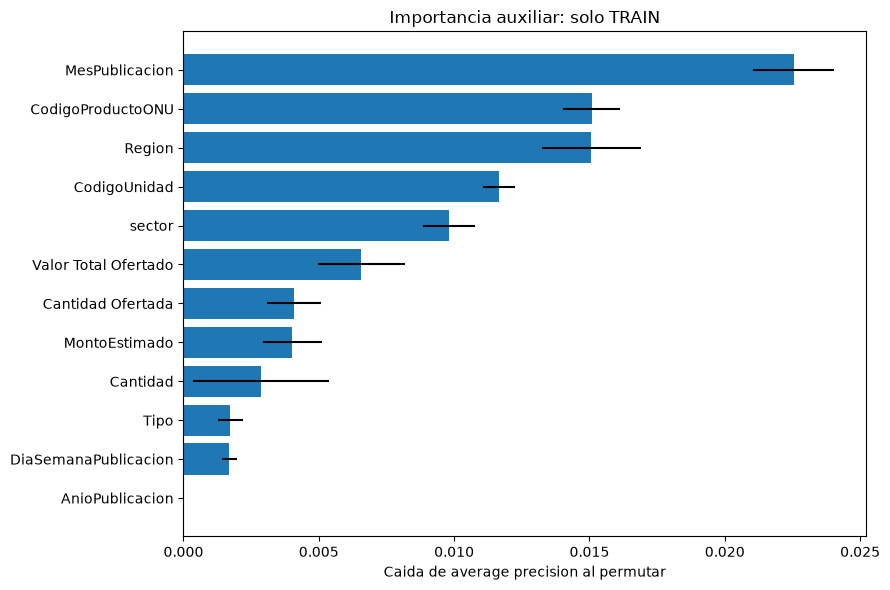

In [13]:
bloques_importancia = {familia.rstrip("_"): cols for familia, cols in familias_onehot.items() if cols}
incluidas_en_familias = {c for cols in bloques_importancia.values() for c in cols}
for c in X.columns:
    if c not in incluidas_en_familias:
        bloques_importancia[c] = [c]
rng_importancia = np.random.default_rng(42)
importancias = []
for bloque, columnas in bloques_importancia.items():
    caidas = []
    for repeticion in range(REPETICIONES_PERMUTACION):
        barajado = X_hold_variables.copy()
        orden = rng_importancia.permutation(len(barajado))
        barajado.loc[:, columnas] = X_hold_variables.iloc[orden][columnas].to_numpy()
        p_barajado = modelo_auxiliar.predict_proba(barajado)[:,1]
        caidas.append(ap_base_variables - average_precision_score(y_hold_variables, p_barajado))
    importancias.append({"variable_o_familia": bloque, "caida_AP_media": float(np.mean(caidas)),
                         "desviacion_permutacion": float(np.std(caidas)), "columnas": columnas})
tabla_importancias = pd.DataFrame(importancias).sort_values("caida_AP_media", ascending=False)
display(tabla_importancias)
fig, ax = plt.subplots(figsize=(9, 6))
vista_importancias = tabla_importancias.sort_values("caida_AP_media")
ax.barh(vista_importancias.variable_o_familia, vista_importancias.caida_AP_media,
        xerr=vista_importancias.desviacion_permutacion)
ax.axvline(0, color="gray")
ax.set(xlabel="Caida de average precision al permutar", title="Importancia auxiliar: solo TRAIN")
fig.tight_layout()
plt.show()

## 1.11. Comprobar retiradas y variables derivadas

Comparamos el modelo auxiliar con variantes: sin constantes, sin CodigoUnidad,
sin CodigoProductoONU y con precio unitario/cobertura de cantidad derivados.
Todas usan el mismo ajuste y la misma muestra interna reservada, sin tocar
validacion principal ni test. No se utiliza presupuesto global como presupuesto
por item. Las derivaciones usan montos y cantidades propios ya disponibles.

Esta exploracion permite proponer cambios, no certificarlos: escoger variantes
mirando esta muestra requiere luego una evaluacion independiente. No se cambia
automaticamente el modelo operativo.

In [14]:
from sklearn.base import clone
variantes_variables = {
    "Todas las variables actuales": (X_fit_variables, X_hold_variables),
    "Sin constantes": (X_fit_variables.drop(columns=constantes_train),
                       X_hold_variables.drop(columns=constantes_train)),
    "Sin CodigoUnidad": (X_fit_variables.drop(columns=["CodigoUnidad"], errors="ignore"),
                         X_hold_variables.drop(columns=["CodigoUnidad"], errors="ignore")),
    "Sin CodigoProductoONU": (X_fit_variables.drop(columns=["CodigoProductoONU"], errors="ignore"),
                              X_hold_variables.drop(columns=["CodigoProductoONU"], errors="ignore"))}
def agregar_derivadas_variables(frame):
    nuevo = frame.copy()
    monto = np.expm1(nuevo["Valor Total Ofertado"])
    ofertada = np.expm1(nuevo["Cantidad Ofertada"])
    solicitada = np.expm1(nuevo["Cantidad"])
    nuevo["log_precio_unitario_oferta"] = np.log1p(monto / ofertada)
    nuevo["log_cobertura_cantidad"] = np.log1p(ofertada / solicitada)
    assert np.isfinite(nuevo[["log_precio_unitario_oferta","log_cobertura_cantidad"]].to_numpy()).all()
    return nuevo
variantes_variables["Con precio unitario y cobertura"] = (
    agregar_derivadas_variables(X_fit_variables), agregar_derivadas_variables(X_hold_variables))
resultados_variantes = []
for nombre, (fit_x, hold_x) in variantes_variables.items():
    if nombre == "Todas las variables actuales":
        p_variante = p_base_variables
    else:
        clasificador = clone(modelo_auxiliar.named_steps["modelo"])
        auxiliar_variante = pipeline_limpio(fit_x, clasificador).fit(fit_x, y_fit_variables)
        p_variante = auxiliar_variante.predict_proba(hold_x)[:,1]
    resultados_variantes.append({"variante": nombre, "columnas": fit_x.shape[1],
        "average_precision": average_precision_score(y_hold_variables, p_variante),
        "ROC_AUC": roc_auc_score(y_hold_variables, p_variante)})
tabla_variantes = pd.DataFrame(resultados_variantes)
tabla_variantes["diferencia_AP"] = tabla_variantes.average_precision - ap_base_variables
display(tabla_variantes.sort_values("average_precision", ascending=False))

,variante,columnas,average_precision,ROC_AUC,diferencia_AP
0,Todas las variables actuales,45,0.277719,0.650210,0.000000
4,Con precio unitario y cobertura,47,0.276805,0.651470,-0.000914
1,Sin constantes,44,0.275904,0.650235,-0.001815
2,Sin CodigoUnidad,44,0.274952,0.648345,-0.002767
3,Sin CodigoProductoONU,44,0.273584,0.649010,-0.004136


## 1.12. Recomendaciones para la depuracion

Las recomendaciones siguientes se generan con los resultados anteriores. No
equivalen a causalidad ni a una seleccion definitiva de variables. La disponibilidad
antes del envio tiene prioridad sobre cualquier importancia estadistica.

In [15]:
print("1. Revisar para retirar por ser constantes en TRAIN:", constantes_train)
print("2. Familias o variables con mayor dependencia del modelo auxiliar:")
display(tabla_importancias[["variable_o_familia","caida_AP_media","desviacion_permutacion"]].head(6))
print("3. Mantener excluidas por disponibilidad:", EXCLUIR)
print("4. No retirar automaticamente variables con importancia nula o negativa: revisar redundancia y estabilidad.")
print("5. Comparacion de variantes, sobre una muestra interna de TRAIN:")
display(tabla_variantes.sort_values("average_precision", ascending=False))
print("6. Antes de incorporar una variante, confirmar con nuevos datos y recuperar claves/fechas de licitacion.")
print("No se modificaron V0.1, el modelo operativo ni sus umbrales.")

1. Revisar para retirar por ser constantes en TRAIN: ['AnioPublicacion']
2. Familias o variables con mayor dependencia del modelo auxiliar:


,variable_o_familia,caida_AP_media,desviacion_permutacion
10,MesPublicacion,0.022543,0.001486
5,CodigoProductoONU,0.015087,0.001053
2,Region,0.015066,0.001820
3,CodigoUnidad,0.011656,0.000579
0,sector,0.009811,0.000972
8,Valor Total Ofertado,0.006571,0.001598


3. Mantener excluidas por disponibilidad: ['NumeroOferentes', 'CantidadReclamos', 'DuracionProceso']
4. No retirar automaticamente variables con importancia nula o negativa: revisar redundancia y estabilidad.
5. Comparacion de variantes, sobre una muestra interna de TRAIN:


,variante,columnas,average_precision,ROC_AUC,diferencia_AP
0,Todas las variables actuales,45,0.277719,0.650210,0.000000
4,Con precio unitario y cobertura,47,0.276805,0.651470,-0.000914
1,Sin constantes,44,0.275904,0.650235,-0.001815
2,Sin CodigoUnidad,44,0.274952,0.648345,-0.002767
3,Sin CodigoProductoONU,44,0.273584,0.649010,-0.004136


6. Antes de incorporar una variante, confirmar con nuevos datos y recuperar claves/fechas de licitacion.
No se modificaron V0.1, el modelo operativo ni sus umbrales.


## Lectura de esta ejecucion sobre el historico de 2024

**Variables con mayor importancia agrupada para el Random Forest auxiliar:**

| Variable o familia | Caida media de average precision al permutar |
|---|---:|
| MesPublicacion | 0,02254 |
| CodigoProductoONU | 0,01509 |
| Region | 0,01507 |
| CodigoUnidad | 0,01166 |
| sector | 0,00981 |
| Valor Total Ofertado | 0,00657 |

Estas caidas indican dependencia del modelo auxiliar en su muestra interna, no
porcentajes de adjudicacion ni efectos causales. El mes puede representar
estacionalidad o particularidades del historico: su primer lugar refuerza la
necesidad de evaluar otros periodos. CodigoUnidad identifica al comprador; su
utilidad con unidades no vistas todavia requiere validacion.

**Depuracion y redundancia:** AnioPublicacion solo contiene 2024 en TRAIN y no
aporta variacion para aprender dentro de este conjunto. Cantidad y Cantidad Ofertada
tienen Spearman 0,999981: son candidatas a una comparacion especifica retirando una
por vez, no a eliminarlas ambas. Las categorias muy raras de Tipo merecen revisar
su soporte antes de interpretar tasas particulares.

**Pruebas retirando variables:** quitar CodigoUnidad redujo average precision
de 0,277719 a 0,274952 y quitar CodigoProductoONU a 0,273584. En esta muestra conviene
conservar ambos como categorias. La variante sin la columna constante obtuvo
0,275904: esa variacion del ajuste no demuestra que una constante aporte informacion.

**Variables derivadas:** precio unitario y cobertura juntos dieron average precision
0,276805 frente a 0,277719 de la base. No hay evidencia de mejora por esa metrica
en esta ejecucion; no se incorporan automaticamente. AUC cambio ligeramente,
de 0,650210 a 0,651470: no todas las metricas mejoran juntas.

**Efecto de los descartes:** las filas conservadas tienen una tasa de seleccion de
16,96%; las descartadas por valores invalidos, aproximadamente 0,0014%. Por tanto,
los resultados se refieren a ofertas con entradas validas, no a cualquier fila
del archivo original. La auditoria es necesaria para interpretar esa poblacion.

**Disponibilidad:** NumeroOferentes muestra asociacion individual, pero sigue fuera
porque no podemos asegurar que sea conocido antes del envio. CantidadReclamos
y DuracionProceso tambien siguen excluidas por esa misma incertidumbre.

El modelo operativo y sus umbrales no cambiaron. Las conclusiones se obtuvieron
sin usar la validacion principal ni test para escoger variables.
